In [2]:
import torch
import matplotlib.pyplot as plt
from transformers import GPT2LMHeadModel

model_name = "openai-community/gpt2"
model = GPT2LMHeadModel.from_pretrained(model_name)
model.eval()

total_params = 0

for name, param in model.named_parameters():
    count = param.numel()
    total_params += count

    print(
        f"{name:55s} "
        f"shape={str(tuple(param.shape)):20s} "
        f"params={count:,}"
    )
print(f"Total Parameters: {total_params:,}")


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

transformer.wte.weight                                  shape=(50257, 768)         params=38,597,376
transformer.wpe.weight                                  shape=(1024, 768)          params=786,432
transformer.h.0.ln_1.weight                             shape=(768,)               params=768
transformer.h.0.ln_1.bias                               shape=(768,)               params=768
transformer.h.0.attn.c_attn.weight                      shape=(768, 2304)          params=1,769,472
transformer.h.0.attn.c_attn.bias                        shape=(2304,)              params=2,304
transformer.h.0.attn.c_proj.weight                      shape=(768, 768)           params=589,824
transformer.h.0.attn.c_proj.bias                        shape=(768,)               params=768
transformer.h.0.ln_2.weight                             shape=(768,)               params=768
transformer.h.0.ln_2.bias                               shape=(768,)               params=768
transformer.h.0.mlp.c_fc.weight      

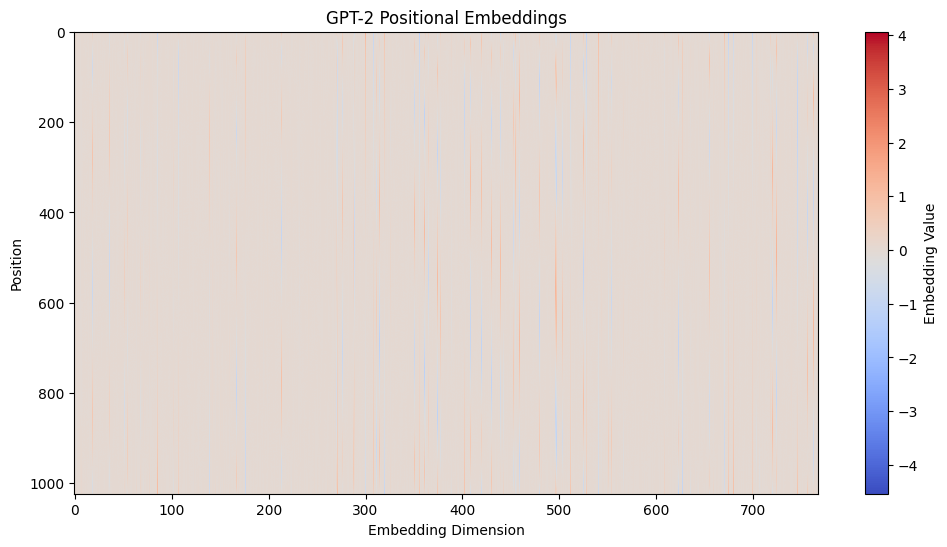

In [3]:
wpe = model.transformer.wpe.weight.detach().cpu().numpy()

plt.figure(figsize=(12, 6))
plt.imshow(wpe, aspect="auto", interpolation="nearest", cmap="coolwarm")
plt.colorbar(label="Embedding Value")
plt.xlabel("Embedding Dimension") # Her pozisyonu temsil eden 768 boyutlu vektör
plt.ylabel("Position")  # 0 dan 1023'e kadar token pozisyonları
plt.title("GPT-2 Positional Embeddings")
plt.show()
# Mavi negatif, kırmızı pozitif ve açık renkler de 0'a yakın değerler

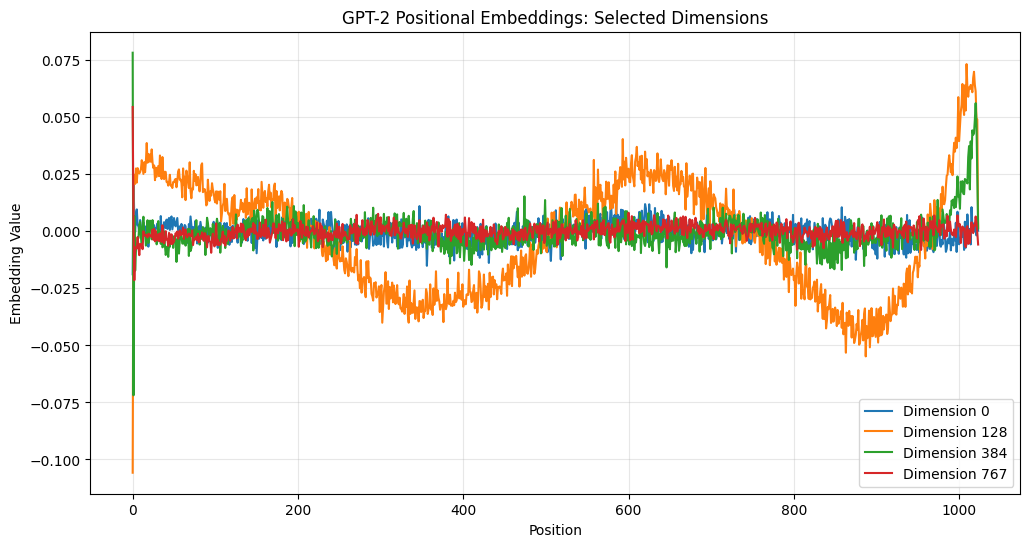

In [4]:
plt.figure(figsize=(12, 6))
dimensions = [0, 128, 384, 767]

for j in dimensions:
    plt.plot(wpe[:, j], label=f"Dimension {j}")

plt.xlabel("Position")
plt.ylabel("Embedding Value")
plt.title("GPT-2 Positional Embeddings:Dimensions")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()